<a href="https://colab.research.google.com/github/iceik973-dotcom/ML1/blob/main/%D0%9B%D0%A012_RNN_LSTM_%D0%93%D1%80%D0%B8%D0%B3%D0%BE%D1%80%D0%B8%D1%88%D0%B5%D0%BD_%D0%92%D0%BB%D0%B0%D0%B4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** ____________________________________  
**Група:** _____________________________________________  
**Дата:** ______________________________________________

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, SimpleRNN, LSTM, Embedding, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

tf.keras.utils.set_random_seed(42)
print("Бібліотеки успішно імпортовано")

Бібліотеки успішно імпортовано


### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [2]:
texts = """Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.."""
print(texts)

Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..


### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [3]:
texts = texts.replace("\ufeff", "")
maxWordsCount = 1000
filters = ' !?.,—–-«»“”";:()[]{}\t\n'
tokenizer = Tokenizer(num_words=maxWordsCount, filters=filters,
                      lower=True, split=' ', char_level=False)
tokenizer.fit_on_texts([texts])
print("Кількість унікальних слів:", len(tokenizer.word_index))
print(dict(list(tokenizer.word_index.items())[:10]))

Кількість унікальних слів: 35
{'не': 1, 'лихо': 2, 'на': 3, 'чом': 4, 'вас': 5, 'в': 6, 'думи': 7, 'мої': 8, 'як': 9, 'мені': 10}


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [4]:
res = np.array(tokenizer.texts_to_sequences([texts])[0])
inp_words = 3
X = np.array([res[i:i + inp_words] for i in range(len(res) - inp_words)])
Y = to_categorical(res[inp_words:], num_classes=maxWordsCount)
print("Розмір X:", X.shape)
print("Розмір Y:", Y.shape)
print("Перший приклад:", X[0])
print("Слова:", ' '.join(tokenizer.index_word[int(i)] for i in X[0]))
print("Цільове слово:", tokenizer.index_word[int(np.argmax(Y[0]))])

Розмір X: (49, 3)
Розмір Y: (49, 1000)
Перший приклад: [7 8 7]
Слова: думи мої думи
Цільове слово: мої


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

In [5]:
model = Sequential([
    Input(shape=(inp_words,), dtype='int32'),
    Embedding(maxWordsCount, 300),
    SimpleRNN(128, activation='tanh', return_sequences=True),
    LSTM(128, activation='tanh'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dense(maxWordsCount, activation='softmax')
])
print("return_sequences=True передає до LSTM всю послідовність прихованих станів, а не лише останній стан.")

return_sequences=True передає до LSTM всю послідовність прихованих станів, а не лише останній стан.


### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [6]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()
print("Кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 300)         │       300,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 3, 128)         │        54,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 632,008 (2.41 MB)

 Trainable params: 632,008 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

Кількість параметрів: 632008


### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [7]:
history = model.fit(X, Y, batch_size=32, epochs=50, verbose=1)
print(f"Кінцеві втрати: {history.history['loss'][-1]:.4f}")
print(f"Кінцева точність: {history.history['accuracy'][-1]:.4f}")

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.0000e+00 - loss: 6.9067
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.2449 - loss: 6.8925
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4490 - loss: 6.8756
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4490 - loss: 6.8532
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4082 - loss: 6.8195
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3469 - loss: 6.7632
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.2857 - loss: 6.6685
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.2449 - loss: 6.5062
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2041 - loss: 6.2061
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1633 - loss: 5.7016
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1633 - loss: 4.8581
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.1224 - loss: 3.98

### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

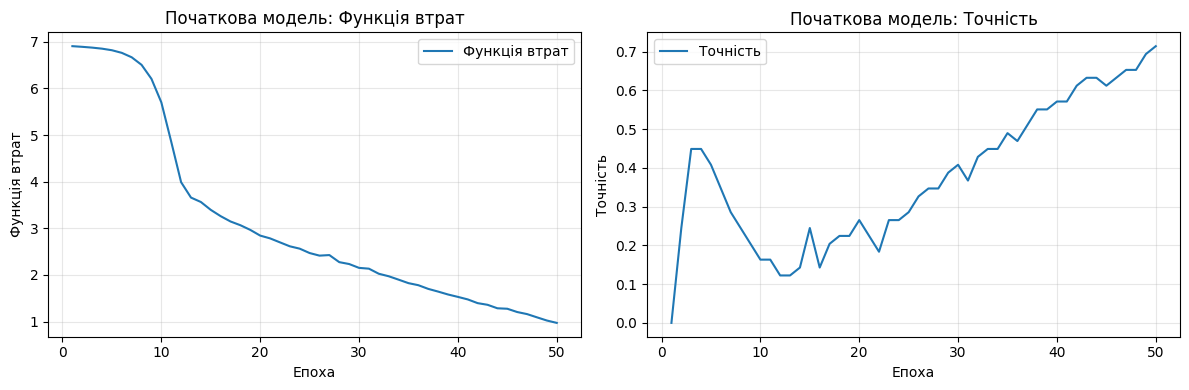

Графіки показують навчальні показники; для оцінки узагальнення потрібні окремі дані.


In [8]:
def plot_history(hist, name):
    epochs = range(1, len(hist.history['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, key, label in zip(axes, ['loss', 'accuracy'], ['Функція втрат', 'Точність']):
        ax.plot(epochs, hist.history[key], label=label)
        ax.set_title(f'{name}: {label}')
        ax.set_xlabel('Епоха')
        ax.set_ylabel(label)
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_history(history, 'Початкова модель')
print("Графіки показують навчальні показники; для оцінки узагальнення потрібні окремі дані.")

### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [9]:
def buildPhrase(texts, str_len=20, network=None):
    network = model if network is None else network
    words = tf.keras.preprocessing.text.text_to_word_sequence(
        texts, filters=tokenizer.filters, lower=True, split=' ')
    unknown = [word for word in words if word not in tokenizer.word_index]
    if unknown:
        raise ValueError("Невідомі слова: " + ', '.join(unknown))
    sequence = tokenizer.texts_to_sequences([texts])[0]
    if len(sequence) < inp_words:
        raise ValueError("Введіть щонайменше три відомі слова.")
    valid_ids = sorted(i for i in tokenizer.index_word if i < maxWordsCount)
    for _ in range(str_len):
        x = np.array([sequence[-inp_words:]])
        prediction = network.predict(x, verbose=0)[0]
        index = valid_ids[int(np.argmax(prediction[valid_ids]))]
        sequence.append(index)
    return ' '.join(tokenizer.index_word[i] for i in sequence)

phrase = buildPhrase('Думи мої думи', 20)
print("Згенерований текст:", phrase)

Згенерований текст: думи мої думи мої лихо мої лихо на лихо на на на породило породило як чом чом вас не не розвіяв в в


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [10]:
%pip install -q keras-tuner
import keras_tuner as kt

### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [11]:
def build_model(hp):
    network = Sequential([
        Input(shape=(inp_words,), dtype='int32'),
        Embedding(maxWordsCount, hp.Int('embedding_dim', 128, 512, step=64)),
        SimpleRNN(hp.Int('rnn_units', 64, 256, step=64), activation='tanh', return_sequences=True),
        LSTM(hp.Int('lstm_units', 64, 256, step=64), activation='tanh'),
        Dropout(hp.Float('dropout_rate', 0.1, 0.5, step=0.1)),
        Dense(hp.Int('dense_units', 64, 256, step=64), activation='relu'),
        Dense(maxWordsCount, activation='softmax')
    ])
    network.compile(optimizer=hp.Choice('optimizer', ['adam', 'rmsprop']),
                    loss='categorical_crossentropy', metrics=['accuracy'])
    return network

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [12]:
tuner = kt.RandomSearch(build_model, objective='accuracy', max_trials=10,
                        executions_per_trial=1, directory='my_tuning',
                        project_name='text_prediction', overwrite=True, seed=42)
tuner.search(X, Y, epochs=10, batch_size=32)
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:")
for key, value in best_hps.values.items():
    print(f"{key}: {value}")

Trial 10 Complete [00h 00m 05s]
accuracy: 0.12244898080825806

Best accuracy So Far: 0.5306122303009033
Total elapsed time: 00h 00m 59s
Найкращі гіперпараметри:
embedding_dim: 384
rnn_units: 64
lstm_units: 128
dropout_rate: 0.2
dense_units: 256
optimizer: adam


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [13]:
best_model = tuner.hypermodel.build(best_hps)
best_history = best_model.fit(X, Y, batch_size=32, epochs=50, verbose=1)
best_model.summary()
print(f"Кінцеві втрати: {best_history.history['loss'][-1]:.4f}")
print(f"Кінцева точність: {best_history.history['accuracy'][-1]:.4f}")

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - accuracy: 0.0000e+00 - loss: 6.9063
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.2449 - loss: 6.8915
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.3265 - loss: 6.8749
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.3265 - loss: 6.8501
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.2857 - loss: 6.8097
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 241ms/step - accuracy: 0.2245 - loss: 6.7478
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step - accuracy: 0.1837 - loss: 6.6329
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 274ms/step - accuracy: 0.1633 - loss: 6.4389
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.1429 - loss: 6.0827
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.1224 - loss: 5.4649
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 282ms/step - accuracy: 0.1224 - loss: 4.5321
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.1020 -

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 384)         │       384,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 64)          │        28,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       257,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,404,730 (9.17 MB)

 Trainable params: 801,576 (3.06 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,603,154 (6.12 MB)

Кінцеві втрати: 0.6570
Кінцева точність: 0.8776


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

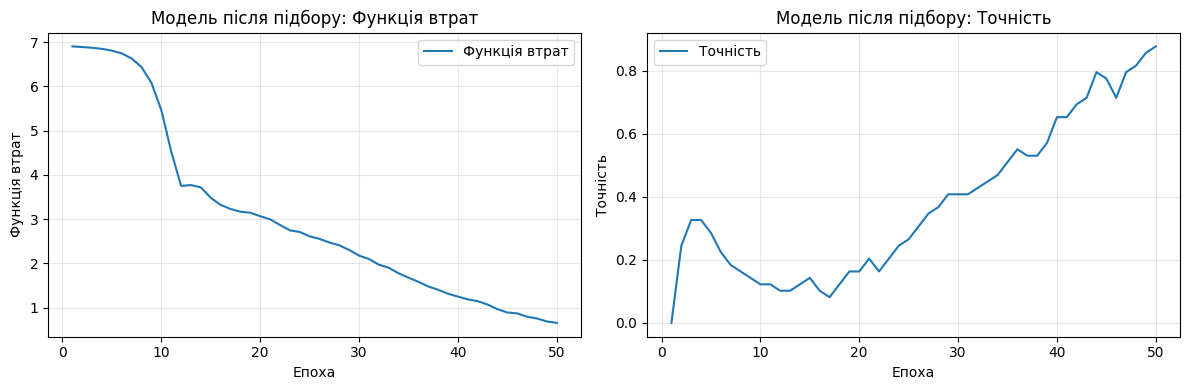

       Модель   Втрати  Точність
    Початкова 0.971954  0.714286
Після підбору 0.656995  0.877551
Початкова модель: думи мої думи мої лихо мої лихо на лихо на на на породило породило як чом чом вас не не розвіяв в в
Модель після підбору: думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як чом
Різниця точності: 0.1633
Через малий корпус обидві моделі можуть повторювати навчальні фрази.


In [14]:
import pandas as pd
plot_history(best_history, 'Модель після підбору')
comparison = pd.DataFrame({
    'Модель': ['Початкова', 'Після підбору'],
    'Втрати': [history.history['loss'][-1], best_history.history['loss'][-1]],
    'Точність': [history.history['accuracy'][-1], best_history.history['accuracy'][-1]]
})
print(comparison.to_string(index=False))
best_phrase = buildPhrase('Думи мої думи', 20, best_model)
print("Початкова модель:", phrase)
print("Модель після підбору:", best_phrase)
print("Різниця точності:", round(comparison['Точність'].iloc[1] - comparison['Точність'].iloc[0], 4))
print("Через малий корпус обидві моделі можуть повторювати навчальні фрази.")

## Висновки
Напишіть власний висновок **5–8 речень**, спираючись на отримані результати. Висвітліть:

1. Яку роль виконують шари `Embedding`, `SimpleRNN`, `LSTM` та `Dropout`?
2. Яких значень `loss` і `accuracy` досягла початкова модель?
3. Які гіперпараметри обрав Keras Tuner?
4. Чи покращилися навчальні показники після підбору параметрів?
5. Наскільки зв’язним був згенерований текст і чому обсяг корпусу важливий?

**Висновок студента:**

Під час роботи було побудовано рекурентну нейронну мережу для передбачення наступного слова. Шар Embedding перетворює слова на вектори, SimpleRNN та LSTM обробляють послідовності, а Dropout зменшує ризик перенавчання. Початкова модель досягла точності ___ та втрат ___. За допомогою Keras Tuner було підібрано параметри: ___. Після підбору точність становила ___, а втрати — ___. Невеликий обсяг навчального тексту обмежує можливість генерації нових зв’язних фраз. Для оцінювання якості моделей на нових текстах необхідна окрема вибірка.

---

### Що потрібно здати
Заповнений файл `.ipynb` з усім власним кодом, результатами виконання, графіками, двома прикладами згенерованого тексту, знайденими гіперпараметрами та висновками.